# Implementation: hallucination-aware, multi-technique prioritization with open-source LLMs

**Base paper:** Sami et al., *Early Results of an AI Multiagent System for Requirements Elicitation and Analysis*, PROFES 2024 (LNCS 15452, pp. 307–316).

| Research gap / problem | What this notebook implements |
|---|---|
| **Gap-1** proprietary models only | Three open-source LLMs run locally (Llama-3.1-8B, Mistral-7B, Qwen2.5-7B) |
| **Gap-2** one technique ($100), one strategy | Three techniques: **100-Dollar, WSJF, AHP**; base-paper multi-agent strategy vs single-call constrained strategy |
| **Gap-3** hallucination and inconsistency under incomplete, ambiguous, dynamic requirements | Perturbation operators + hallucination auditor + **reduction methods**: M1 constrained output (valid ids, exact length, valid value ranges), M2 audit-and-repair loop, M3 self-consistency (Borda over runs) |

**Data (this step):** S0 Supplier Data Management Platform (base paper; 12 stories frozen from our reproduction), S1 Courseware System and S2 DigitalHome (PURE SRS, from Curto et al., RAISE '26, doi:10.5281/zenodo.17501425; fixed seeded subset of 12 requirements each). S3–S5 (LIS, LOG, UNI) are added in the next step.

**Compared methods:** B0 = base-paper multi-agent (PO, QA, Developer + Manager; free JSON) · M1 = proposed constrained output · M2 = M1 + audit-and-repair · M3 = M2 + self-consistency.

**How to run:** Runtime → Change runtime type → **T4 GPU**, then Runtime → Run all (about 1.5 h; results are saved to Google Drive, so after a disconnect run Cells 1–9 and Cell 10 again — finished jobs are skipped).

## Cell 1 - GPU check and installation (Ollama + Python packages)

In [ ]:
# Runtime -> Change runtime type -> T4 GPU, then run this cell.
!nvidia-smi
!sudo apt-get -qq update > /dev/null && sudo apt-get -qq install -y zstd pciutils lshw > /dev/null
!curl -fsSL https://ollama.com/install.sh | sh
!pip -q install sentence-transformers scipy pandas matplotlib requests

Thu Nov 12 04:32:06 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   55C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## Cell 2 - Start Ollama (4 parallel requests) and download the three open-source models

In [ ]:
import subprocess, time, requests, os
def ollama_up(timeout=120):
    def alive():
        try: return requests.get("http://127.0.0.1:11434/api/tags", timeout=5).ok
        except requests.exceptions.RequestException: return False
    subprocess.run(["pkill", "-f", "ollama serve"]); time.sleep(2)
    env = {**os.environ, "OLLAMA_NUM_PARALLEL": "4", "OLLAMA_MAX_LOADED_MODELS": "1",
           "OLLAMA_FLASH_ATTENTION": "1", "OLLAMA_KV_CACHE_TYPE": "q8_0", "OLLAMA_KEEP_ALIVE": "60m"}
    subprocess.Popen(["ollama", "serve"], stdout=open("/content/ollama.log", "w"), stderr=subprocess.STDOUT, env=env)
    t0 = time.time()
    while time.time() - t0 < timeout:
        if alive(): print(f"Ollama started in {time.time()-t0:.0f}s"); return True
        time.sleep(2)
    raise RuntimeError("Ollama did not start - see /content/ollama.log")
ollama_up()
MODELS = ["llama3.1:8b", "mistral:7b", "qwen2.5:7b"]
from concurrent.futures import ThreadPoolExecutor
with ThreadPoolExecutor(3) as ex:
    list(ex.map(lambda m: subprocess.run(["ollama", "pull", m], check=True, capture_output=True), MODELS))
!ollama list

Ollama started in 9s
NAME           ID              SIZE      MODIFIED               
llama3.1:8b    46e0c10c039e    4.9 GB    Less than a second ago    
qwen2.5:7b     845dbda0ea48    4.7 GB    2 seconds ago             
mistral:7b     6577803aa9a0    4.4 GB    9 seconds ago             


## Cell 3 - Configuration (results are saved to Google Drive and survive a disconnect)

In [ ]:
import os, json, pathlib
try:
    from google.colab import drive
    drive.mount("/content/drive"); OUT = pathlib.Path("/content/drive/MyDrive/llm_rp_hallucination")
except Exception:
    OUT = pathlib.Path("./llm_rp_hallucination")
OUT.mkdir(parents=True, exist_ok=True)
LOG = OUT / "runs.jsonl"

ACTIVE_SCENARIOS = ["S0_SDMP", "S1_CWS", "S2_HOM"]               # this step; add "S3_LIS", "S4_LOG", "S5_UNI" later
MODELS      = ["llama3.1:8b", "mistral:7b", "qwen2.5:7b"]        # Gap-1: open-source LLMs
TECHNIQUES  = ["100_dollar", "wsjf", "ahp"]                       # Gap-2: three prioritization techniques
CONDITIONS  = ["incomplete", "ambiguous", "dynamic"]              # Gap-3: degraded inputs ("clean" is the control)
RUNS_CLEAN  = 3       # proposed method, clean input
RUNS_PERT   = 2       # proposed method, each perturbed condition
RUNS_B0     = 2       # base-paper baseline (4 LLM calls per run)
B0_PERTURBED_SCENARIOS = ["S0_SDMP"]   # baseline on degraded input: the base paper's own project
MAX_REPAIR  = 1       # audit-and-repair rounds (M2)
WORKERS     = 4       # must equal OLLAMA_NUM_PARALLEL
TEMPERATURE = 0.7
NUM_CTX     = 4096
SEED0       = 42
QUICK       = False   # True = 1 model, 2 scenarios, 1 run: a 5-minute smoke test
print("results ->", OUT)

Mounted at /content/drive
results -> /content/drive/MyDrive/llm_rp_hallucination


## Cell 4 - Dataset: base-paper project (SDMP) + five published SRS projects (PURE / CLASS)

In [ ]:
# S0: Supplier Data Management Platform from the base paper (Sami et al., PROFES 2024); its 12 user stories are frozen
#     from our reproduction of the base paper (Llama-3.1-8B, run 1).
# S1-S5: Curto, Semini & Marques-Neto, RAISE '26 (doi:10.1145/3786174.3788352), dataset doi:10.5281/zenodo.17501425.
#     Description = the published overall description; requirements = a fixed, seeded subset of 12 ground-truth
#     functional requirements (random.Random(2026)), so that AHP stays feasible (66 pairs). Full lists are kept.
ALL_SCENARIOS = json.loads(r"""{
 "S0_SDMP": {
  "name": "Supplier Data Management Platform",
  "source": "Base paper (Sami et al., PROFES 2024); stories frozen from the reproduction (Llama-3.1-8B, run 1)",
  "description": "This project addresses the challenge of managing and comparing data from over 500 vendors. The current system struggles with vendor diversity and cost tracking. The new platform will streamline data extraction from PDFs, translate and structure it for LLM use, and store it in MongoDB. The goal is to enable real-time analysis and provide insights into supplier offerings through a functional demo. The main features include identifying and comparing pricing information from various suppliers, recommending the best suppliers based on the data, and calculating the total cost of procurement. Use cases include ingredient and cost analysis for lasagna, supplier rate comparison for pasta, and recipe cost calculation. Future plans include API development for data uploads and enhanced analysis for better procurement and cost management.",
  "kind": "user_story",
  "n_total": 12,
  "requirements": [
   {
    "id": 1,
    "orig_id": 1,
    "text": "As a data analyst, I want to extract pricing information from PDFs, so that I can compare vendor offerings in a structured format."
   },
   {
    "id": 2,
    "orig_id": 2,
    "text": "As a data analyst, I want to translate extracted data into a standardized format for LLM use, so that I can analyze vendor data accurately."
   },
   {
    "id": 3,
    "orig_id": 3,
    "text": "As a data analyst, I want to store vendor data in a MongoDB database, so that I can easily retrieve and compare data from various vendors."
   },
   {
    "id": 4,
    "orig_id": 4,
    "text": "As a procurement manager, I want to enable real-time analysis of vendor data through a user-friendly interface, so that I can make informed decisions about supplier selection and pricing."
   },
   {
    "id": 5,
    "orig_id": 5,
    "text": "As a procurement manager, I want to compare pricing information from various suppliers, so that I can identify the best vendors for our needs."
   },
   {
    "id": 6,
    "orig_id": 6,
    "text": "As a procurement manager, I want to receive recommendations for the best suppliers based on vendor data, so that I can streamline our procurement process."
   },
   {
    "id": 7,
    "orig_id": 7,
    "text": "As a procurement manager, I want to calculate the total cost of procurement, so that I can optimize our costs and make better purchasing decisions."
   },
   {
    "id": 8,
    "orig_id": 8,
    "text": "As a recipe developer, I want to analyze ingredient costs and optimize recipes, so that I can reduce our expenses and improve product offerings."
   },
   {
    "id": 9,
    "orig_id": 9,
    "text": "As a procurement manager, I want to compare supplier rates for pasta, so that I can identify the best vendors for our pasta needs."
   },
   {
    "id": 10,
    "orig_id": 10,
    "text": "As a recipe developer, I want to calculate the cost of recipes, so that I can ensure that our products are competitively priced and profitable."
   },
   {
    "id": 11,
    "orig_id": 11,
    "text": "As a data analyst, I want to develop APIs for data uploads, so that we can easily integrate vendor data into our system."
   },
   {
    "id": 12,
    "orig_id": 12,
    "text": "As a procurement manager, I want to enable enhanced analysis of vendor data through a user-friendly interface, so that I can make more informed decisions about supplier selection and pricing."
   }
  ]
 },
 "S1_CWS": {
  "name": "Courseware System",
  "source": "Curto, Semini & Marques-Neto, RAISE '26 (doi:10.1145/3786174.3788352), dataset doi:10.5281/zenodo.17501425; origin PURE",
  "description": "The software is designed as an enhancement to an existing courseware system, focusing on improving educational management and learning experiences through modular additions and refinements. It provides capabilities for managing course content, facilitating assignment submissions, supporting collaborative tools, enabling audio-based learning activities, and delivering notifications to users. The primary users include students who consume content and submit work, professors who administer courses and assess assignments, and system administrators who maintain the system and its configurations. The system operates within a web-based environment, accessible through standard browsers over typical campus or internet networks, and is expected to run on common server platforms. It must adhere to established educational technology standards, integrate with existing institutional authentication and data systems, and comply with relevant accessibility and data protection policies. The software assumes stable network connectivity, reliance on external authentication services for user management, and dependency on third-party components for features such as web feeds and social tools.",
  "kind": "shall",
  "n_total": 20,
  "requirements": [
   {
    "id": 1,
    "orig_id": 4,
    "text": "The system must store audio clips in a format conducive to speech."
   },
   {
    "id": 2,
    "orig_id": 7,
    "text": "An actor must be able to search through pages in a course."
   },
   {
    "id": 3,
    "orig_id": 9,
    "text": "A course administrator must be able to grade an assignment."
   },
   {
    "id": 4,
    "orig_id": 10,
    "text": "The system should display grade information to the appropriate actor."
   },
   {
    "id": 5,
    "orig_id": 11,
    "text": "The system should maintain a grade history."
   },
   {
    "id": 6,
    "orig_id": 13,
    "text": "The system must provide a blog engine."
   },
   {
    "id": 7,
    "orig_id": 15,
    "text": "The system must be backed up on a configurable schedule."
   },
   {
    "id": 8,
    "orig_id": 16,
    "text": "The system should be available 24 hours a day, 7 days a week."
   },
   {
    "id": 9,
    "orig_id": 17,
    "text": "The system should support at least 1000 concurrent users."
   },
   {
    "id": 10,
    "orig_id": 18,
    "text": "The system must be maintainable without substantial modification."
   },
   {
    "id": 11,
    "orig_id": 19,
    "text": "Users must have easy access to help while interacting with the system."
   },
   {
    "id": 12,
    "orig_id": 20,
    "text": "System administrators must have access to comprehensive, searchable documentation."
   }
  ]
 },
 "S2_HOM": {
  "name": "DigitalHome",
  "source": "Curto, Semini & Marques-Neto, RAISE '26 (doi:10.1145/3786174.3788352), dataset doi:10.5281/zenodo.17501425; origin PURE",
  "description": "The system operates as an independent home automation platform centered around a central gateway device that connects to a home's broadband Internet and communicates wirelessly with various environmental controllers, sensors, and appliances. It enables remote monitoring and control of home systems through a web server interface accessible from web-ready computers, cell phones, or PDAs. The system integrates with a home's existing infrastructure to manage climate, security, and appliance states. The system provides capabilities for environmental control including temperature and humidity regulation, comprehensive home security management with contact sensors and alarms, and appliance management for lighting and small appliances. It supports planning and scheduling of home parameters and generates historical reports on system operation and events. Users can monitor real-time conditions and override automated settings as needed. The system is designed for homeowners or residents who possess basic technical literacy to operate web and mobile interfaces. Users are expected to understand fundamental concepts of home climate control, security systems, and appliance management. The interface accommodates users accessing the system remotely for monitoring and control tasks without requiring advanced programming skills. The software operates in a residential environment, interfacing with a central home server and gateway device connected to a broadband Internet network. It communicates wirelessly with distributed sensors and controllers throughout the home. The system is accessible through standard web browsers on computers and mobile devices, requiring no specific proprietary platforms or unusual network configurations. The system must adhere to American Society of Heating, Refrigerating and Air-Conditioning Engineers standards for environmental control systems. It must maintain compatibility with centralized HVAC systems using various energy sources including gas, oil, electricity, and solar. The implementation requires wireless communication protocols for device connectivity and web standards for remote access interfaces. The system assumes the presence of reliable broadband Internet connectivity and continuous electrical power in the home environment. It depends on proper installation and functioning of wireless communication infrastructure between the gateway and peripheral devices. The system requires compatible HVAC systems and assumes standard residential electrical systems for appliance management functionality.",
  "kind": "shall",
  "n_total": 42,
  "requirements": [
   {
    "id": 1,
    "orig_id": 1,
    "text": "The DigitalHome System shall allow a web-ready computer, cell phone or PDA to control a home's temperature, humidity, lights, security, and the state of small appliances."
   },
   {
    "id": 2,
    "orig_id": 7,
    "text": "The DigitalHome programmable thermostat shall allow a user to monitor and control a home’s temperature from any location, using a web ready computer, cell phone, or PDA."
   },
   {
    "id": 3,
    "orig_id": 8,
    "text": "A DH user shall be able to read the temperature at a thermostat position."
   },
   {
    "id": 4,
    "orig_id": 15,
    "text": "A thermostat unit shall communicate, through wireless signals, with the master control unit."
   },
   {
    "id": 5,
    "orig_id": 16,
    "text": "The system shall support Fahrenheit and Celsius temperature values."
   },
   {
    "id": 6,
    "orig_id": 21,
    "text": "Up to eight humidistats shall be placed in rooms throughout the home."
   },
   {
    "id": 7,
    "orig_id": 27,
    "text": "A DigitalHome system shall be able to manage up to fifty door and window contact sensors."
   },
   {
    "id": 8,
    "orig_id": 29,
    "text": "When a security breach occurs and a contact sensor is set OPEN, the alarm system shall be activated."
   },
   {
    "id": 9,
    "orig_id": 32,
    "text": "The system shall be able to provide information about the state of a power switch (OFF or ON), indicating whether an appliance connected to the power switch is OFF or ON."
   },
   {
    "id": 10,
    "orig_id": 33,
    "text": "The system shall be able to change the state of a power switch (OFF to ON, or ON to OFF), in turn changing the state of an appliance connected to the power switch."
   },
   {
    "id": 11,
    "orig_id": 36,
    "text": "DigitalHome provides a monthly planner."
   },
   {
    "id": 12,
    "orig_id": 40,
    "text": "The month report shall contain daily average, maximum (with time) and minimum (with time) values of temperature and humidity for each thermostat and humidistat, respectively."
   }
  ]
 }
}""")
SCENARIOS = {k: ALL_SCENARIOS[k] for k in ACTIVE_SCENARIOS}
if QUICK:
    SCENARIOS = {k: SCENARIOS[k] for k in list(SCENARIOS)[:2]}
    MODELS, RUNS_CLEAN, RUNS_PERT, RUNS_B0 = MODELS[:1], 1, 1, 1
for k, v in SCENARIOS.items():
    print(f"{k:8s} {v['name'][:32]:32s} {len(v['requirements']):2d} of {v['n_total']:2d} requirements | {len(v['description'].split())} words")

S0_SDMP  Supplier Data Management Platfor 12 of 12 requirements | 124 words
S1_CWS   Courseware System                12 of 20 requirements | 154 words
S2_HOM   DigitalHome                      12 of 42 requirements | 337 words


## Cell 5 - Controlled perturbations (incomplete, ambiguous, dynamic) for user stories and 'shall' requirements

In [ ]:
import re, random, copy
def sents(t): return [s for s in re.split(r"(?<=[.!?])\s+", t.strip()) if s]

CUT_US = re.compile(r",?\s+(so that|in order to|to ensure|so I can|so we can)\b.*$", re.I)
CUT_SH = re.compile(r"\s*(,|;|:| -)\s*(so that|in order to|including|such as|e\.g\.|which|that is|indicating|in turn|at which time|"
                    r"through|using|via|for|from|with|to)\b.*$|\s+(so that|in order to|through|using|via|from any location|in case of)\b.*$", re.I)
def incomplete_req(t, kind):
    s = re.sub(r"\s*\([^)]*\)", "", t).strip().rstrip(".")
    cut = (CUT_US if kind == "user_story" else CUT_SH).sub("", s).strip()
    if len(cut.split()) < 5: cut = s
    if cut == s and "," in s and len(s.split(",")[0].split()) >= 5:   # no clause to remove: drop the detail after the first comma
        cut = s.split(",")[0].strip()
    if cut == s:                                                      # still unchanged: drop a trailing detail phrase
        m = list(re.finditer(r"\s(in|at|on|for|without|within|throughout|after|before|during|by|from|via|with)\s", s))
        if m and len(s[:m[-1].start()].split()) >= 5: cut = s[:m[-1].start()].strip()
    return cut + "."

def ambiguous_req(t, kind):
    s = t.strip().rstrip(".")
    s = re.sub(r"\b\d+([.,]\d+)?\s*%?", "some", s)
    s = re.sub(r"\b(one|two|three|four|five|six|seven|eight|nine|ten|twelve|twenty|fifty|hundred)\b", "some", s, flags=re.I)
    ACR = r"\b(?!OFF\b|ON\b)[A-Z]{2,}[A-Za-z0-9-]*\b"
    s = re.sub(r"\b(a|an|the|A|An|The)\s+" + ACR, lambda m: ("The" if m.group(1)[0].isupper() else "the") + " relevant", s)
    s = re.sub(ACR, "the relevant component", s)
    if kind == "user_story":
        s = re.sub(r"\bI want to\b", "I might want to somehow", s, count=1)
    else:
        s = re.sub(r"\b(shall|must)\b", "should probably", s, count=1)
    return s + ", or something similar, as appropriate."

NEW_REQ = {"user_story": "As a manager, I want an audit log of all changes to the data, so that every modification can be traced.",
           "shall": "The system shall keep an audit log of all data changes made by users."}

def scenario_variant(sid, condition):
    """Return (scenario dict with 'description' and 'requirements', meta). Deterministic for every model."""
    sc = copy.deepcopy(SCENARIOS[sid]); kind = sc["kind"]; reqs = sc["requirements"]
    meta = {"condition": condition, "deleted": [], "changed": None, "added": None}
    if condition == "incomplete":
        sc["description"] = " ".join(sents(sc["description"])[:2])
        for r in reqs: r["text"] = incomplete_req(r["text"], kind)
    elif condition == "ambiguous":
        sc["description"] = ambiguous_req(" ".join(sents(sc["description"])[:3]), "shall").replace(", or something similar, as appropriate.", ".")
        for r in reqs: r["text"] = ambiguous_req(r["text"], kind)
    elif condition == "dynamic":
        rng = random.Random(sum(map(ord, sid)) + 7)
        ids = [r["id"] for r in reqs]
        changed = rng.choice(ids[len(ids) // 2:])
        deleted = sorted(rng.sample([i for i in ids if i != changed], 2))
        new_id = max(ids) + 1
        reqs = [r for r in reqs if r["id"] not in deleted]
        for r in reqs:
            if r["id"] == changed: r["text"] = "[CHANGE REQUEST - now mandatory for the next release] " + r["text"]
        reqs.append({"id": new_id, "orig_id": None, "text": NEW_REQ[kind]})
        sc["description"] += (f" Change request for this iteration: requirement {changed} is now mandatory for the next release, "
                              f"requirements {deleted[0]} and {deleted[1]} were dropped, and requirement {new_id} was added.")
        meta.update(deleted=deleted, changed=changed, added=new_id)
    sc["requirements"] = reqs
    return sc, meta

demo = list(SCENARIOS)[-1]
sc, meta = scenario_variant(demo, "clean");      print("clean:     ", sc["requirements"][0]["text"])
sc, meta = scenario_variant(demo, "incomplete"); print("incomplete:", sc["requirements"][0]["text"])
sc, meta = scenario_variant(demo, "ambiguous");  print("ambiguous: ", sc["requirements"][0]["text"])
sc, meta = scenario_variant("S0_SDMP", "dynamic");   print("dynamic:   ", meta)

clean:      The DigitalHome System shall allow a web-ready computer, cell phone or PDA to control a home's temperature, humidity, lights, security, and the state of small appliances.
incomplete: The DigitalHome System shall allow a web-ready computer.
ambiguous:  The DigitalHome System should probably allow a web-ready computer, cell phone or the relevant component to control a home's temperature, humidity, lights, security, and the state of small appliances, or something similar, as appropriate.
dynamic:    {'condition': 'dynamic', 'deleted': [1, 8], 'changed': 9, 'added': 13}


## Cell 6 - Ollama client (JSON schema = constrained decoding, or plain JSON mode for the baseline)

In [ ]:
import time, requests
def chat(model, system, user, fmt, seed, num_predict=900, retries=2):
    """fmt = a JSON schema (constrained decoding) or "json" (free JSON, as close as possible to the base paper)."""
    body = {"model": model, "stream": False, "format": fmt,
            "messages": [{"role": "system", "content": system}, {"role": "user", "content": user}],
            "options": {"temperature": TEMPERATURE, "seed": seed, "num_ctx": NUM_CTX, "num_predict": num_predict}}
    last = ""
    for attempt in range(retries + 1):
        t0 = time.time()
        try:
            r = requests.post("http://127.0.0.1:11434/api/chat", json=body, timeout=900); r.raise_for_status()
            j = r.json(); last = j["message"]["content"]
            info = {"latency_s": round(time.time() - t0, 2), "out_tokens": j.get("eval_count"), "attempts": attempt + 1}
            if j.get("done_reason") == "length":
                raise json.JSONDecodeError("truncated at num_predict", last, 0)
            return json.loads(last), info
        except (requests.exceptions.RequestException, json.JSONDecodeError, KeyError) as e:
            last = f"{type(e).__name__}: {e}"; body["options"]["seed"] += 7; time.sleep(1)
    return None, {"latency_s": None, "error": last[:300], "attempts": retries + 1}

## Cell 7 - Prompts: base-paper multi-agent baseline (B0) and proposed constrained prompting (M1/M2)

In [ ]:
FIB = [1, 2, 3, 5, 8, 13, 20]
SAATY = [1, 2, 3, 4, 5, 6, 7, 8, 9, -2, -3, -4, -5, -6, -7, -8, -9]
RULES = {
 "100_dollar": "Apply the 100-Dollar (cumulative voting) technique: distribute exactly 100 points over ALL requirements; more points = higher priority. Points are non-negative and must sum to exactly 100.",
 "wsjf": "Apply Weighted Shortest Job First (WSJF): for EVERY requirement give bv (business value), tc (time criticality), rr (risk reduction / opportunity enablement) and js (job size), each using only 1, 2, 3, 5, 8, 13 or 20.",
 "ahp": "Apply the Analytic Hierarchy Process (AHP): for EVERY pair listed below give s = Saaty's intensity (1 equal, 3 moderate, 5 strong, 7 very strong, 9 extreme; 2/4/6/8 in between). Use a positive s if requirement a is more important and a negative s if requirement b is more important. Keep the judgements transitive (if a > b and b > c then a > c).",
}
EXAMPLE = {"100_dollar": '{"items": [{"id": 1, "points": 20, "why": "..."}]}',
           "wsjf": '{"items": [{"id": 1, "bv": 8, "tc": 5, "rr": 3, "js": 5, "why": "..."}]}',
           "ahp": '{"pairs": [{"a": 1, "b": 2, "s": 3}]}'}
SYSTEM = ("You are an experienced requirements engineer. Prioritize the requirements of the project below. Use ONLY the "
          "information given. Refer to requirements only by the ids listed and do not invent requirements. Keep every 'why' "
          "to at most eight words. Return only JSON.")
ROLE = {  # base paper (Sami et al., PROFES 2024): Product Owner, QA and Developer agents, then a Manager agent
 "PO":  "You are the Product Owner. You prioritize requirements according to business value and stakeholder needs.",
 "QA":  "You are the Quality Assurance agent. You prioritize requirements by ensuring coverage, quality and effectiveness.",
 "Dev": "You are a senior developer. You prioritize requirements by technical constraints, dependencies and effort.",
}
MANAGER = "You are the Manager agent. You make the final prioritization from the discussion of the Product Owner, QA and Developer agents."

def pairs_of(ids): return [(a, b) for k, a in enumerate(ids) for b in ids[k + 1:]]

def user_prompt(sc, tech):
    ids = [r["id"] for r in sc["requirements"]]
    req = "\n".join(f"[{r['id']}] {r['text']}" for r in sc["requirements"])
    extra = ("\nPairs (a, b) to compare: " + " ".join(f"({a},{b})" for a, b in pairs_of(ids))) if tech == "ahp" else ""
    return f"Project description:\n{sc['description']}\n\nRequirements:\n{req}\n\nTechnique: {RULES[tech]}{extra}\nValid ids: {ids}"

def schema(tech, ids):
    """Proposed method: constrained decoding - only valid ids, exact list length, valid value ranges."""
    ID = {"type": "integer", "enum": ids}
    if tech == "ahp":
        n = len(pairs_of(ids))
        item = {"type": "object", "properties": {"a": ID, "b": ID, "s": {"type": "integer", "enum": SAATY}}, "required": ["a", "b", "s"]}
        return {"type": "object", "properties": {"pairs": {"type": "array", "minItems": n, "maxItems": n, "items": item}}, "required": ["pairs"]}
    props = {"id": ID, "why": {"type": "string"}}
    if tech == "100_dollar": props["points"] = {"type": "number", "minimum": 0}
    else: props.update({k: {"type": "integer", "enum": FIB} for k in ("bv", "tc", "rr", "js")})
    item = {"type": "object", "properties": props, "required": list(props)}
    return {"type": "object", "properties": {"items": {"type": "array", "minItems": len(ids), "maxItems": len(ids), "items": item}}, "required": ["items"]}

def tokens_for(tech, n):
    return int(1.6 * (40 + (14 * n * (n - 1) // 2 if tech == "ahp" else (60 if tech == "wsjf" else 32) * n)))

def baseline_prompt(sc, tech):
    return user_prompt(sc, tech) + f"\nReturn JSON in exactly this format: {EXAMPLE[tech]}"

def manager_prompt(sc, tech, role_out):
    disc = "\n\n".join(f"{r} agent:\n{json.dumps(o)}" for r, o in role_out.items())
    return (user_prompt(sc, tech) + f"\n\nDiscussion so far:\n{disc}\n\nCombine the three inputs into the FINAL prioritization "
            f"with the same technique. Return JSON in exactly this format: {EXAMPLE[tech]}")

def repair_prompt(sc, tech, prev, issues):
    return (user_prompt(sc, tech) + "\n\nYour previous answer:\n" + json.dumps(prev) +
            "\n\nAn automatic check found these problems:\n- " + "\n- ".join(issues) +
            "\nReturn a corrected and complete answer that fixes every problem.")
print(user_prompt(scenario_variant("S0_SDMP", "clean")[0], "100_dollar")[:700])

Project description:
This project addresses the challenge of managing and comparing data from over 500 vendors. The current system struggles with vendor diversity and cost tracking. The new platform will streamline data extraction from PDFs, translate and structure it for LLM use, and store it in MongoDB. The goal is to enable real-time analysis and provide insights into supplier offerings through a functional demo. The main features include identifying and comparing pricing information from various suppliers, recommending the best suppliers based on the data, and calculating the total cost of procurement. Use cases include ingredient and cost analysis for lasagna, supplier rate comparison f


## Cell 8 - Hallucination auditor and scoring (works on any output, valid or not)

In [ ]:
import numpy as np
from scipy.stats import rankdata
RI = {1: 0, 2: 0, 3: .58, 4: .90, 5: 1.12, 6: 1.24, 7: 1.32, 8: 1.41, 9: 1.45, 10: 1.49, 11: 1.51, 12: 1.48, 13: 1.56, 14: 1.57, 15: 1.59}
def as_int(x):
    try: return int(x)
    except Exception: return None

def analyse(sc, tech, out, meta):
    ids = [r["id"] for r in sc["requirements"]]; valid = set(ids); n = len(ids)
    res = {"parse_ok": isinstance(out, dict), "issues": []}
    if not res["parse_ok"]:
        res.update(F=np.nan, Om=1.0, Dup=np.nan, G=0, H=1, V=1, ranks=None, rationales={}, points_total=np.nan, CR=np.nan, coverage=0.0)
        res["issues"] = ["The output was not valid JSON."]; return res
    rows = out.get("pairs" if tech == "ahp" else "items") or []
    rows = [r for r in rows if isinstance(r, dict)]
    mentioned = [as_int(r.get(k)) for r in rows for k in (("a", "b") if tech == "ahp" else ("id",))]
    mentioned = [m for m in mentioned if m is not None]
    U = set(mentioned)
    fab = sorted(U - valid); miss = sorted(valid - U); ghosts = sorted(U & set(meta.get("deleted") or []))
    if tech == "ahp":
        keys = [tuple(sorted((as_int(r.get("a")), as_int(r.get("b"))))) for r in rows]
        dup = len(keys) - len(set(keys)); res["Dup"] = dup / len(keys) if keys else 0.0
        dups = []
    else:
        res["Dup"] = (len(mentioned) - len(U)) / len(mentioned) if mentioned else 0.0
        dups = sorted({m for m in mentioned if mentioned.count(m) > 1})
    res["F"] = len(fab) / len(U) if U else 0.0
    res["Om"] = len(miss) / n
    res["G"] = int(bool(ghosts))
    res["H"] = int(res["F"] > 0 or res["Dup"] > 0 or res["G"] == 1)
    if fab: res["issues"].append(f"Ids {fab} do not exist; use only the valid ids {ids}.")
    if ghosts: res["issues"].append(f"Requirements {ghosts} were dropped and must not be ranked.")
    if miss and tech != "ahp": res["issues"].append(f"Requirements {miss} are missing; include every requirement exactly once.")
    if dups: res["issues"].append(f"Requirements {dups} appear more than once; give each requirement exactly once.")
    score, rat, viol = {}, {}, bool(miss) or bool(fab) or bool(dups) or bool(ghosts)
    res.update(points_total=np.nan, CR=np.nan, coverage=np.nan)
    if tech == "100_dollar":
        for r in rows:
            i = as_int(r.get("id"))
            if i in valid and i not in score:
                try: score[i] = float(r.get("points", 0))
                except Exception: score[i] = 0.0
                rat[i] = str(r.get("why", ""))
        tot = round(sum(score.values()), 2); res["points_total"] = tot
        if abs(tot - 100) > 1 or any(v < 0 for v in score.values()):
            viol = True; res["issues"].append(f"The points sum to {tot}; they must be non-negative and sum to exactly 100.")
    elif tech == "wsjf":
        bad = []
        for r in rows:
            i = as_int(r.get("id"))
            if i in valid and i not in score:
                f = [as_int(r.get(k)) for k in ("bv", "tc", "rr", "js")]
                if any(v not in FIB for v in f): bad.append(i)
                f = [v if v is not None else 1 for v in f]
                score[i] = (f[0] + f[1] + f[2]) / max(f[3], 1); rat[i] = str(r.get("why", ""))
        if bad: viol = True; res["issues"].append(f"WSJF values of requirements {bad} are not in 1, 2, 3, 5, 8, 13, 20.")
    else:
        pos = {i: k for k, i in enumerate(ids)}; A = np.ones((n, n)); seen = set()
        for r in rows:
            a, b, s = as_int(r.get("a")), as_int(r.get("b")), as_int(r.get("s"))
            if a in pos and b in pos and a != b and s is not None and tuple(sorted((a, b))) not in seen:
                seen.add(tuple(sorted((a, b)))); w = float(min(max(abs(s), 1), 9))
                hi, lo = (a, b) if s > 0 else (b, a); A[pos[hi], pos[lo]] = w; A[pos[lo], pos[hi]] = 1 / w
        need = set(pairs_of(ids)); cov = len(seen & need) / len(need) if need else 1.0; res["coverage"] = cov
        vals, vecs = np.linalg.eig(A); k = np.argmax(vals.real); w = np.abs(vecs[:, k].real); w = w / w.sum()
        lam = vals.real[k]; cr = ((lam - n) / (n - 1)) / RI.get(n, 1.59) if n > 2 else 0.0; res["CR"] = round(float(cr), 3)
        score = {i: w[pos[i]] for i in ids}
        missing_pairs = sorted(need - seen)
        if missing_pairs:
            viol = True; res["issues"].append(f"These pairs are missing: {missing_pairs[:30]}{' ...' if len(missing_pairs) > 30 else ''}. Compare every listed pair.")
        if cr > 0.10:
            viol = True; res["issues"].append(f"The consistency ratio is {cr:.2f} (must be <= 0.10). Revise the judgements so they are transitive.")
    res["V"] = int(viol)
    if score:
        full = {i: score.get(i, -1e9) for i in ids}                       # missing requirements share the lowest rank
        rk = rankdata([-full[i] for i in ids], method="average"); res["ranks"] = {i: float(r) for i, r in zip(ids, rk)}
    else:
        res["ranks"] = None
    res["rationales"] = rat
    return res

## Cell 9 - Experiment runner: B0 (base paper) and M (M1 = constrained output, M2 = M1 + audit-and-repair)

In [ ]:
import hashlib, datetime, threading
from concurrent.futures import ThreadPoolExecutor, as_completed

def job_key(**k): return hashlib.md5(json.dumps(k, sort_keys=True).encode()).hexdigest()
def done_keys():
    if not LOG.exists(): return set()
    return {json.loads(l)["job"] for l in open(LOG) if l.strip()}

def record(base, method, out, a, calls, sc):
    return {**base, "method": method, "raw": out, **{k: v for k, v in a.items()},
            "n_calls": len(calls), "latency_s": round(sum(c.get("latency_s") or 0 for c in calls), 2),
            "errors": [c["error"] for c in calls if "error" in c],
            "req_ids": [r["id"] for r in sc["requirements"]], "req_text": {r["id"]: r["text"] for r in sc["requirements"]}}

def run_job(sid, model, tech, cond, method, run):
    sc, meta = scenario_variant(sid, cond); ids = [r["id"] for r in sc["requirements"]]
    seed = SEED0 + 1000 * run; cap = tokens_for(tech, len(ids))
    base = {"scenario": sid, "model": model, "technique": tech, "condition": cond, "run": run, "seed": seed, "meta": meta}
    if method == "B0":
        def role_call(item):
            role, sys = item
            return role, chat(model, sys + " Return only JSON.", baseline_prompt(sc, tech), "json", seed, cap)
        with ThreadPoolExecutor(3) as ex: res = list(ex.map(role_call, ROLE.items()))
        calls = [info for _, (_, info) in res]; role_out = {role: o for role, (o, _) in res}
        out, info = chat(model, MANAGER + " Return only JSON.", manager_prompt(sc, tech, role_out), "json", seed, cap)
        calls.append(info)
        return [record(base, "B0", out, analyse(sc, tech, out, meta), calls, sc)]
    sch = schema(tech, ids)
    out, info = chat(model, SYSTEM, user_prompt(sc, tech), sch, seed, cap); calls = [info]
    a = analyse(sc, tech, out, meta)
    recs = [record(base, "M1", out, a, list(calls), sc)]
    for k in range(MAX_REPAIR):                      # audit-and-repair loop
        if not a["issues"]: break
        new, info = chat(model, SYSTEM, repair_prompt(sc, tech, out if out else {}, a["issues"]), sch, seed + 100 + k, cap)
        calls.append(info)
        if new is not None:
            out, a = new, analyse(sc, tech, new, meta)
    recs.append(record(base, "M2", out, a, calls, sc))
    return recs

_lock = threading.Lock()
def warm_up(model):
    requests.post("http://127.0.0.1:11434/api/generate", json={"model": model, "prompt": "", "keep_alive": "60m"}, timeout=600)

def run_grid(scenarios, models, techniques, conditions, method, runs, label):
    done = done_keys()
    for m in models:
        jobs = [(job_key(s=s, m=m, t=t, c=c, me=method, r=r), s, t, c, r)
                for s in scenarios for t in techniques for c in conditions for r in range(1, runs + 1)]
        jobs = [j for j in jobs if j[0] not in done]
        print(f"[{label}] {m}: {len(jobs)} jobs to run")
        if not jobs: continue
        warm_up(m); t0 = time.time(); n = 0
        with ThreadPoolExecutor(WORKERS) as ex:
            futs = {ex.submit(run_job, s, m, t, c, method, r): (k, s, t, c) for k, s, t, c, r in jobs}
            for f in as_completed(futs):
                k, s, t, c = futs[f]
                try: recs = f.result()
                except Exception as e: print("   job failed:", s, t, c, type(e).__name__, e); continue
                with _lock, open(LOG, "a") as fh:
                    for rec in recs:
                        rec.update(job=k, exp=label, time=datetime.datetime.now().isoformat(timespec="seconds"))
                        fh.write(json.dumps(rec, default=str) + "\n")
                n += 1
                if n % 10 == 0 or n == len(jobs):
                    el = time.time() - t0; print(f"   {n}/{len(jobs)}  {el/60:.1f} min  eta {el/n*(len(jobs)-n)/60:.1f} min")

## Cell 10 - Run all experiments, one model at a time (resumable)

In [ ]:
# Per model (3 scenarios): M clean 27 jobs, B0 clean 18 jobs (4 calls each), M perturbed 54 jobs, B0 perturbed on SDMP 18 jobs.
# About 270-300 LLM calls per model, roughly 25-35 min per model on a T4 (about 1.5 h for all three models).
T0 = time.time(); S = list(SCENARIOS)
for m in MODELS:
    print(f"\n================ {m} ================")
    run_grid(S, [m], TECHNIQUES, ["clean"], "M", RUNS_CLEAN, "M_clean")
    run_grid(S, [m], TECHNIQUES, ["clean"], "B0", RUNS_B0, "B0_clean")
    run_grid(S, [m], TECHNIQUES, CONDITIONS, "M", RUNS_PERT, "M_perturbed")
    run_grid([s for s in B0_PERTURBED_SCENARIOS if s in SCENARIOS], [m], TECHNIQUES, CONDITIONS, "B0", RUNS_B0, "B0_perturbed")
    print(f"{m} finished - {(time.time()-T0)/60:.1f} min so far")

recs = [json.loads(l) for l in open(LOG) if l.strip()]
jobs = {r["job"] for r in recs}
exp_jobs = len(MODELS) * len(TECHNIQUES) * (len(S) * (RUNS_CLEAN + RUNS_B0 + len(CONDITIONS) * RUNS_PERT)
                                             + len([s for s in B0_PERTURBED_SCENARIOS if s in S]) * len(CONDITIONS) * RUNS_B0)
print(f"\nJobs done: {len(jobs)} of {exp_jobs} | output records: {len(recs)} | unparsable outputs: {sum(not r['parse_ok'] for r in recs)}")
print("CHECK:", "OK - run Cells 11-14" if len(jobs) >= exp_jobs else "NOT OK - run Cells 1-9 and this cell again")


================ llama3.1:8b ================
[M_clean] llama3.1:8b: 27 jobs to run
   10/27  5.3 min  eta 9.0 min
   20/27  9.8 min  eta 3.4 min
   27/27  15.5 min  eta 0.0 min
[B0_clean] llama3.1:8b: 18 jobs to run
   10/18  15.4 min  eta 12.3 min
   18/18  24.5 min  eta 0.0 min
[M_perturbed] llama3.1:8b: 54 jobs to run
   10/54  2.1 min  eta 9.1 min
   20/54  8.0 min  eta 13.5 min
   30/54  10.3 min  eta 8.2 min
   40/54  16.0 min  eta 5.6 min
   50/54  20.5 min  eta 1.6 min
   54/54  24.6 min  eta 0.0 min
[B0_perturbed] llama3.1:8b: 18 jobs to run
   10/18  12.6 min  eta 10.1 min
   18/18  21.9 min  eta 0.0 min
llama3.1:8b finished - 87.9 min so far

================ mistral:7b ================
[M_clean] mistral:7b: 27 jobs to run
   10/27  4.0 min  eta 6.8 min
   20/27  8.7 min  eta 3.0 min
   27/27  12.9 min  eta 0.0 min
[B0_clean] mistral:7b: 18 jobs to run
   10/18  13.4 min  eta 10.7 min
   18/18  22.0 min  eta 0.0 min
[M_perturbed] mistral:7b: 54 jobs to run
   10/54  2.8 mi

## Cell 11 - Metrics: hallucination, validity, consistency, robustness, agreement; M3 = self-consistency

In [ ]:
import itertools, pandas as pd
from scipy.stats import kendalltau
from sentence_transformers import SentenceTransformer
recs = [json.loads(l) for l in open(LOG) if l.strip()]
for r in recs:
    r["ranks"] = {int(k): v for k, v in r["ranks"].items()} if r.get("ranks") else None
    r["req_text"] = {int(k): v for k, v in r["req_text"].items()}
    r["rationales"] = {int(k): v for k, v in (r.get("rationales") or {}).items()}
df = pd.DataFrame(recs)
print(len(df), "records;", df.groupby("method").size().to_dict())

def tau(a, b):
    ids = [i for i in a if i in b]
    if len(ids) < 3: return np.nan
    t = kendalltau([a[i] for i in ids], [b[i] for i in ids]).statistic
    return np.nan if t is None else float(t)
def borda(rank_dicts):
    rank_dicts = [d for d in rank_dicts if d]
    if not rank_dicts: return {}
    ids = sorted(set().union(*rank_dicts)); avg = {i: np.mean([d[i] for d in rank_dicts if i in d]) for i in ids}
    return dict(zip(ids, rankdata([avg[i] for i in ids], method="average")))

# M3 = self-consistency: Borda aggregation of the M2 runs of one configuration (targets inconsistent outputs)
m3 = []
for (s, m, t, c), g in df[df.method == "M2"].groupby(["scenario", "model", "technique", "condition"]):
    agg = borda(g.ranks.tolist())
    if agg:
        m3.append({"scenario": s, "model": m, "technique": t, "condition": c, "run": 0, "method": "M3", "ranks": agg,
                   "meta": g.meta.iloc[0], "req_ids": g.req_ids.iloc[0], "n_calls": g.n_calls.sum(), "latency_s": g.latency_s.sum(),
                   "parse_ok": True})
df = pd.concat([df, pd.DataFrame(m3)], ignore_index=True)

# consensus reference (no ground truth): leave-one-model-out Borda of the clean M2 runs of the other models
clean_m2 = df[(df.method == "M2") & (df.condition == "clean")]
CONS = {(s, t, m): borda(clean_m2[(clean_m2.scenario == s) & (clean_m2.technique == t) & (clean_m2.model != m)].ranks.tolist())
        for s in SCENARIOS for t in TECHNIQUES for m in MODELS}
df["tau_consensus"] = [tau(r.ranks, CONS.get((r.scenario, r.technique, r.model), {})) if r.ranks and r.condition == "clean" else np.nan
                       for r in df.itertuples()]

# stability: perturbed output vs the same model + method on clean input (common requirements only)
CLEAN = {k: borda(g.ranks.tolist()) for k, g in df[df.condition == "clean"].groupby(["scenario", "model", "technique", "method"])}
df["tau_clean"] = [tau(r.ranks, CLEAN.get((r.scenario, r.model, r.technique, r.method), {})) if r.ranks and r.condition != "clean" else np.nan
                   for r in df.itertuples()]

def urgent_shift(r):
    if r.condition != "dynamic" or not r.ranks: return np.nan
    c = r.meta["changed"]; cc = CLEAN.get((r.scenario, r.model, r.technique, r.method), {})
    if c not in cc or c not in r.ranks: return np.nan
    return cc[c] / len(cc) - r.ranks[c] / len(r.ranks)              # > 0 = the changed requirement moved up
df["urgent_shift"] = [urgent_shift(r) for r in df.itertuples()]

# ungrounded rationale: cosine(reason, requirement) < 0.20 (all-MiniLM-L6-v2)
emb = SentenceTransformer("all-MiniLM-L6-v2")
def ungrounded(r):
    rat = r.rationales if isinstance(r.rationales, dict) else {}
    pairs = [(rat[i], r.req_text[i]) for i in rat if rat[i] and i in (r.req_text if isinstance(r.req_text, dict) else {})]
    if not pairs: return np.nan
    A = emb.encode([a for a, _ in pairs], normalize_embeddings=True); B = emb.encode([b for _, b in pairs], normalize_embeddings=True)
    return float(np.mean((A * B).sum(1) < 0.20))
df["Ug"] = [ungrounded(r) for r in df.itertuples()]

# run-to-run consistency per configuration
rows = []
for (s, m, t, c, me), g in df[df.method != "M3"].groupby(["scenario", "model", "technique", "condition", "method"]):
    rl = [x for x in g.ranks.tolist() if x]
    pr = [tau(a, b) for a, b in itertools.combinations(rl, 2)]
    rows.append({"scenario": s, "model": m, "technique": t, "condition": c, "method": me, "run_tau": np.nanmean(pr) if pr else np.nan})
cons = pd.DataFrame(rows)
print("metrics done")

594 records; {'B0': 108, 'M1': 243, 'M2': 243}


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (6 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

metrics done


/tmp/ipykernel_512/3870599666.py:67: RuntimeWarning: Mean of empty slice
  rows.append({"scenario": s, "model": m, "technique": t, "condition": c, "method": me, "run_tau": np.nanmean(pr) if pr else np.nan})


## Cell 12 - Result tables + statistical tests

In [ ]:
from scipy.stats import wilcoxon
T = {}
H_COLS = ["parse_ok", "F", "Om", "Dup", "G", "H", "V", "Ug"]
base = df[df.method.isin(["B0", "M1", "M2"])].copy(); base["parse_ok"] = base.parse_ok.astype(float)
T["hallucination_by_method"] = base.groupby(["method"])[H_COLS + ["n_calls", "latency_s"]].mean().round(3)
T["hallucination_by_method_technique"] = base.groupby(["technique", "method"])[H_COLS].mean().round(3)
T["hallucination_by_method_model"] = base.groupby(["model", "method"])[["H", "V", "Om", "Ug"]].mean().round(3)
T["hallucination_by_scenario"] = base.groupby(["scenario", "method"])[["H", "V", "Om"]].mean().round(3)
T["hallucination_by_condition"] = base[base.scenario.isin(B0_PERTURBED_SCENARIOS)].groupby(["condition", "method"])[["H", "V", "Om", "G", "Ug"]].mean().round(3)
ahp = base[base.technique == "ahp"]; dol = base[base.technique == "100_dollar"]
T["technique_validity"] = pd.concat([ahp.groupby("method").agg(AHP_CR_median=("CR", "median"), AHP_CR_ok=("CR", lambda x: float(np.mean(x <= 0.10))),
                                                              AHP_coverage=("coverage", "mean")),
                                     dol.groupby("method").agg(Dollar_sum_ok=("points_total", lambda x: float(np.mean(np.abs(x - 100) <= 1))))], axis=1).round(3)
T["consistency_clean"] = cons[cons.condition == "clean"].pivot_table(index="technique", columns="method", values="run_tau", aggfunc="mean").round(3)
T["agreement_consensus_clean"] = df[df.condition == "clean"].pivot_table(index="technique", columns="method", values="tau_consensus", aggfunc="mean").round(3)
T["stability_by_condition"] = df[df.condition != "clean"].pivot_table(index="condition", columns="method", values="tau_clean", aggfunc="mean").round(3)
T["dynamic"] = df[df.condition == "dynamic"].groupby("method").agg(ghost=("G", "mean"), urgent_shift=("urgent_shift", "mean")).round(3)
T["cost"] = df.groupby("method")[["n_calls", "latency_s"]].mean().round(1)

stats = []
def paired(col, a, b, data):
    g = data.groupby(["scenario", "model", "technique", "condition", "method"])[col].mean().unstack("method")
    g = g[[a, b]].dropna()
    if len(g) < 6 or (g[a] - g[b]).abs().sum() == 0: return (f"{col}: {a} vs {b}", np.nan, np.nan, len(g))
    w = wilcoxon(g[a], g[b]); return (f"{col}: {a} vs {b} (mean {g[a].mean():.3f} -> {g[b].mean():.3f})", float(w.statistic), float(w.pvalue), len(g))
for col in ["V", "H", "Om"]:
    for a, b in [("B0", "M1"), ("M1", "M2"), ("B0", "M2")]:
        stats.append(paired(col, a, b, base))
st = pd.DataFrame(stats, columns=["test", "statistic", "p", "n"])
pv = st.p.fillna(1).values; order = np.argsort(pv); adj = np.empty_like(pv); run_max = 0
for k, i in enumerate(order): run_max = max(run_max, (len(pv) - k) * pv[i]); adj[i] = min(1, run_max)
st["p_holm"] = adj; st["p"] = st.p.map(lambda p: "n/a" if pd.isna(p) else ("< 0.001" if p < 0.001 else f"{p:.4f}"))
st["p_holm"] = st.p_holm.map(lambda p: "< 0.001" if p < 0.001 else f"{p:.4f}")
T["statistics"] = st
for k, v in T.items():
    v.to_csv(OUT / f"table_{k}.csv"); print(f"\n==== {k} ====\n{v}")


==== hallucination_by_method ====
        parse_ok      F     Om    Dup      G      H      V     Ug  n_calls  \
method                                                                       
B0         0.972  0.007  0.044  0.017  0.056  0.176  0.824  0.022    4.000   
M1         1.000  0.000  0.000  0.001  0.000  0.016  0.584  0.032    1.000   
M2         1.000  0.000  0.000  0.001  0.000  0.012  0.576  0.032    1.584   

        latency_s  
method             
B0        447.010  
M1         59.360  
M2         94.205  

==== hallucination_by_method_technique ====
                   parse_ok      F     Om    Dup      G      H      V     Ug
technique  method                                                           
100_dollar B0         1.000  0.002  0.017  0.013  0.028  0.139  0.972  0.002
           M1         1.000  0.000  0.001  0.001  0.000  0.012  0.864  0.039
           M2         1.000  0.000  0.000  0.000  0.000  0.000  0.840  0.039
ahp        B0         0.972  0.018  0.046  0

## Cell 13 - Figures

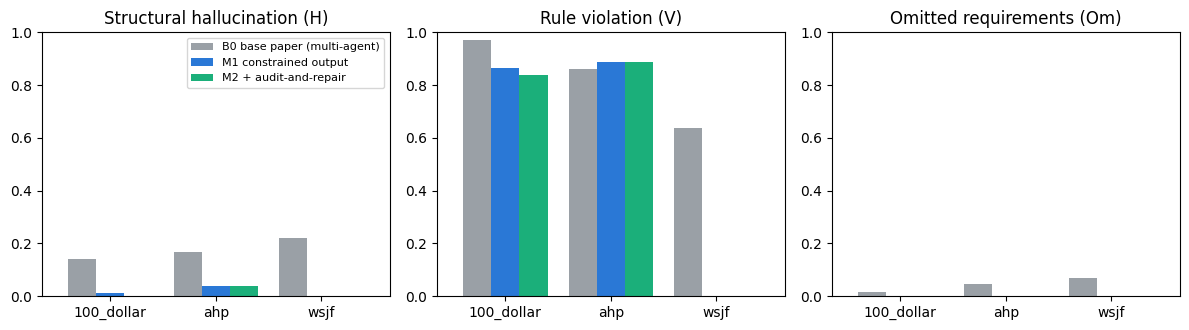

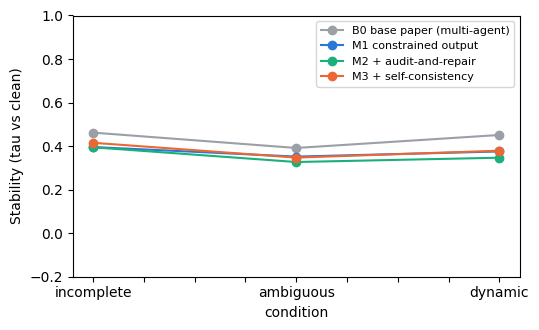

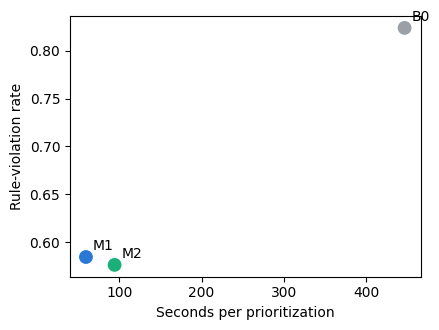

In [ ]:
import matplotlib.pyplot as plt
FIG = OUT / "figures"; FIG.mkdir(exist_ok=True)
MC = {"B0": "#9aa0a6", "M1": "#2a78d6", "M2": "#1baf7a", "M3": "#eb6834"}
LBL = {"B0": "B0 base paper (multi-agent)", "M1": "M1 constrained output", "M2": "M2 + audit-and-repair", "M3": "M3 + self-consistency"}
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
for a, col, title in zip(ax, ["H", "V", "Om"], ["Structural hallucination (H)", "Rule violation (V)", "Omitted requirements (Om)"]):
    p = base.pivot_table(index="technique", columns="method", values=col, aggfunc="mean").reindex(columns=["B0", "M1", "M2"])
    p.plot.bar(ax=a, color=[MC[c] for c in p.columns], rot=0, legend=False, width=0.8); a.set_title(title); a.set_ylim(0, 1); a.set_xlabel("")
ax[0].legend([LBL[c] for c in ["B0", "M1", "M2"]], fontsize=8); plt.tight_layout(); plt.savefig(FIG / "fig_hallucination_reduction.png", dpi=200); plt.show()

p = df[df.condition != "clean"].pivot_table(index="condition", columns="method", values="tau_clean", aggfunc="mean").reindex(["incomplete", "ambiguous", "dynamic"])
ax = p.plot(marker="o", figsize=(5.5, 3.4), color=[MC[c] for c in p.columns]); ax.set_ylabel("Stability (tau vs clean)"); ax.set_ylim(-0.2, 1)
ax.legend([LBL[c] for c in p.columns], fontsize=8); plt.tight_layout(); plt.savefig(FIG / "fig_stability.png", dpi=200); plt.show()

c = base.groupby("method").agg(V=("V", "mean"), sec=("latency_s", "mean"))
ax = c.plot.scatter(x="sec", y="V", s=80, c=[MC[m] for m in c.index], figsize=(4.5, 3.4))
for m, r in c.iterrows(): ax.annotate(m, (r.sec, r.V), xytext=(5, 5), textcoords="offset points")
ax.set_xlabel("Seconds per prioritization"); ax.set_ylabel("Rule-violation rate"); plt.tight_layout(); plt.savefig(FIG / "fig_cost_vs_violation.png", dpi=200); plt.show()

## Cell 14 - Save summary and download everything

In [ ]:
def flat(v):
    v = v.copy()
    if isinstance(v.columns, pd.MultiIndex): v.columns = ["_".join(map(str, c)) for c in v.columns]
    return json.loads(v.reset_index().to_json(orient="records"))
summary = {"models": MODELS, "techniques": TECHNIQUES, "scenarios": {k: v["name"] for k, v in SCENARIOS.items()},
           "records": len(df), "tables": {k: flat(v) for k, v in T.items()}}
(OUT / "summary.json").write_text(json.dumps(summary, indent=1, default=str))
import shutil
shutil.make_archive("/content/llm_rp_hallucination_results", "zip", OUT)
try:
    from google.colab import files; files.download("/content/llm_rp_hallucination_results.zip")
except Exception:
    print("zip at /content/llm_rp_hallucination_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>